# PERSUADE 2.0: DISCOURSE EFFECTIVENESS CLASSIFICATION
## DeBERTa-v3-base Single Model Training & Multi-Metric Evaluation

Local Windows setup. Training requires a CUDA-enabled PyTorch installation and an NVIDIA GPU; the setup cell stops with an error if CUDA is unavailable, so the model cannot silently run on CPU. Put `persuade_corpus_2.0_train.csv` in `dataset/` (or the project root). Outputs are written to `outputs/`.


### Section 0: Local Setup & Environment Initialization

This section imports the required packages, checks that the local Python environment can see an NVIDIA CUDA GPU, enables FP16 mixed precision, sets reproducible seeds, and loads the local training CSV plus `outputs/split_assignments.csv` when present.


In [1]:
# Local dependencies must already be installed in the active Python environment.

import os
import sys
import gc
import json
import time
import math
import random
import warnings
import argparse
from typing import Dict, List, Tuple, Any

# Ensure UTF-8 output on Windows consoles
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")
if hasattr(sys.stderr, "reconfigure"):
    sys.stderr.reconfigure(encoding="utf-8")

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Dependencies must be installed in the active local environment. Use a CUDA-enabled
# PyTorch build; this notebook intentionally does not install a CPU-only torch build.

import numpy as np
import pandas as pd
import scipy.optimize
import scipy.special
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

import torch
import torch.nn as nn
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)
from datasets import Dataset

# ------------------------------------------------------------------------------
# 0.1 Reproducibility Seed Initialization
# ------------------------------------------------------------------------------
RANDOM_SEED = 42

def enforce_reproducibility(seed: int = RANDOM_SEED) -> None:
    """Set global seeds for Python, NumPy, PyTorch, and Transformers."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    set_seed(seed)
    print(f"[Setup] Deterministic random seed fixed to: {seed}")

enforce_reproducibility(RANDOM_SEED)

# ------------------------------------------------------------------------------
# 0.2 Local NVIDIA GPU & FP16 Configuration (required)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("SECTION 0: LOCAL GPU & ENVIRONMENT VERIFICATION")
print("=" * 80)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable to this Python environment. This notebook requires "
        "the CUDA-enabled PyTorch build and will not continue on CPU. In Jupyter, "
        "select the project's .venv kernel after installing CUDA-enabled PyTorch."
    )

DEVICE = torch.device("cuda:0")
DEVICE_NAME = torch.cuda.get_device_name(0)
DEVICE_COUNT = torch.cuda.device_count()
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
USE_FP16 = True
print(f"[Hardware] NVIDIA GPU: {DEVICE_NAME} (Count: {DEVICE_COUNT}, VRAM: {VRAM_GB:.2f} GB)")
print("[Hardware] CUDA training device: cuda:0")
print("[Hardware] FP16 mixed precision: ENABLED")
# ------------------------------------------------------------------------------
# 0.4 Argument Parsing & Runtime Configuration
# ------------------------------------------------------------------------------
parser = argparse.ArgumentParser(description="DeBERTa-v3-base Single Evaluation Pipeline for PERSUADE 2.0")
parser.add_argument("--data_path", type=str, default=os.path.join(os.getcwd(), "dataset", "persuade_corpus_2.0_train.csv"), help="Path to train CSV")
parser.add_argument("--output_dir", type=str, default="outputs", help="Directory to store outputs")
parser.add_argument("--quick", action="store_true", help="Run quick demo on small subset to verify pipeline execution")
parser.add_argument("--eval_only", action="store_true", help="Skip training and run evaluation on saved checkpoint")
parser.add_argument("--epochs", type=int, default=3, help="Number of training epochs (default: 3)")
parser.add_argument("--batch_size", type=int, default=8, help="Per-device train batch size (default: 8)")
parser.add_argument("--grad_accum", type=int, default=4, help="Gradient accumulation steps (default: 4)")
parser.add_argument("--lr", type=float, default=2e-5, help="Learning rate (default: 2e-5)")
parser.add_argument("--max_length", type=int, default=512, help="Max sequence length (default: 512)")
parser.add_argument("--bootstrap_b", type=int, default=2000, help="Bootstrap iterations (default: 2000)")

# Ignore extra arguments supplied by the Jupyter kernel
args, _ = parser.parse_known_args()

OUTPUT_DIR = args.output_dir
os.makedirs(OUTPUT_DIR, exist_ok=True)
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "deberta_checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ------------------------------------------------------------------------------
# 0.5 Dataset Loading and Split Resolution
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("SECTION 0: DATASET LOADING & SPLIT INTEGRITY VERIFICATION")
print("=" * 80)

# Resolve the local training CSV path (dataset/ first, project root as fallback)
if os.path.exists(args.data_path):
    data_path = args.data_path
else:
    alt_path = os.path.join(os.getcwd(), "persuade_corpus_2.0_train.csv")
    if os.path.exists(alt_path):
        data_path = alt_path
    else:
        raise FileNotFoundError(
            f"Training CSV not found. Looked for '{args.data_path}' and '{alt_path}'. "
            "Place persuade_corpus_2.0_train.csv in the project dataset/ folder, "
            "or set args.data_path to its local path."
        )
print(f"[Data] Loading PERSUADE Corpus 2.0 from: {data_path}")
load_start = time.time()

# Read needed columns with robust string casting for ID columns
needed_cols = [
    "essay_id", "discourse_id", "discourse_text",
    "discourse_type", "discourse_effectiveness"
]

raw_df = pd.read_csv(data_path, usecols=needed_cols, low_memory=False)
raw_count = len(raw_df)

# Filter out rows with missing discourse_effectiveness or missing discourse_text
df = raw_df.dropna(subset=["discourse_effectiveness", "discourse_text"]).copy()
df["discourse_text"] = df["discourse_text"].astype(str).str.strip()
df["discourse_type"] = df["discourse_type"].astype(str).str.strip()
df = df[df["discourse_text"].str.len() > 0].reset_index(drop=True)

# Normalize essay_id and discourse_id as clean strings
df["essay_id"] = df["essay_id"].astype(str).str.strip()
df["discourse_id"] = df["discourse_id"].astype(str).str.strip()

print(f"[Data] Loaded {raw_count:,} total records in {time.time() - load_start:.2f}s.")
print(f"[Data] Valid labeled discourse units: {len(df):,} across {df['essay_id'].nunique():,} unique essays.")

# Split assignment resolution
split_file_path = os.path.join(OUTPUT_DIR, "split_assignments.csv")
if os.path.exists(split_file_path):
    print(f"[Split] Found existing split assignments at: {split_file_path}")
    split_df = pd.read_csv(split_file_path)
    split_df["essay_id"] = split_df["essay_id"].astype(str).str.strip()
    split_map = dict(zip(split_df["essay_id"], split_df["split"]))
    df["split"] = df["essay_id"].map(split_map)
    # If any essays were missing from split file, handle gracefully
    if df["split"].isna().any():
        print("[Split] WARNING: Some essays were not present in existing split file. Recreating consistent split.")
        create_new_split = True
    else:
        create_new_split = False
else:
    print(f"[Split] '{split_file_path}' not found. Generating reproducible GroupShuffleSplit (80/20, seed={RANDOM_SEED})...")
    create_new_split = True

if create_new_split:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_SEED)
    train_idx, val_idx = next(gss.split(df, groups=df["essay_id"]))
    df["split"] = "train"
    df.iloc[val_idx, df.columns.get_loc("split")] = "val"
    
    # Save split assignments for downstream classical baselines and team reproducibility
    split_assignments = df[["essay_id", "split"]].drop_duplicates().reset_index(drop=True)
    split_assignments.to_csv(split_file_path, index=False)
    print(f"[Split] Exported consistent split assignments to: {split_file_path}")

# Verify split distributions
train_units = (df["split"] == "train").sum()
val_units = (df["split"] == "val").sum()
train_essays = df[df["split"] == "train"]["essay_id"].nunique()
val_essays = df[df["split"] == "val"]["essay_id"].nunique()
total_essays = df["essay_id"].nunique()

print(f"\n[Split Integrity Check]")
print(f"  * Train Set     : {train_units:,} units ({train_units / len(df) * 100:.2f}%) | {train_essays:,} essays ({train_essays / total_essays * 100:.2f}%)")
print(f"  * Validation Set: {val_units:,} units ({val_units / len(df) * 100:.2f}%) | {val_essays:,} essays ({val_essays / total_essays * 100:.2f}%)")

# Assert strict zero-leakage guarantee
train_essay_set = set(df[df["split"] == "train"]["essay_id"].unique())
val_essay_set = set(df[df["split"] == "val"]["essay_id"].unique())
overlap = train_essay_set.intersection(val_essay_set)
assert len(overlap) == 0, f"DATA LEAKAGE ERROR: {len(overlap)} essays overlap between train and val splits!"
print("[Split Integrity Check] PASSED: Strict essay-level isolation confirmed (0 essay overlap).")

# If running in --quick mode, subsample for rapid validation
if args.quick:
    print("\n[*] Quick Demo Mode Enabled: Downsampling dataset for rapid pipeline smoke testing...")
    sampled_train_essays = random.sample(list(train_essay_set), min(80, len(train_essay_set)))
    sampled_val_essays = random.sample(list(val_essay_set), min(20, len(val_essay_set)))
    df = df[df["essay_id"].isin(sampled_train_essays + sampled_val_essays)].reset_index(drop=True)
    train_units = (df["split"] == "train").sum()
    val_units = (df["split"] == "val").sum()
    print(f"[*] Quick Subset Size: Train units = {train_units:,}, Val units = {val_units:,}")




D:\School\Year4\MLA\final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Setup] Deterministic random seed fixed to: 42

SECTION 0: LOCAL GPU & ENVIRONMENT VERIFICATION
[Hardware] NVIDIA GPU: NVIDIA GeForce RTX 4070 SUPER (Count: 1, VRAM: 11.99 GB)
[Hardware] CUDA training device: cuda:0
[Hardware] FP16 mixed precision: ENABLED

SECTION 0: DATASET LOADING & SPLIT INTEGRITY VERIFICATION
[Data] Loading PERSUADE Corpus 2.0 from: D:\School\Year4\MLA\final\dataset\persuade_corpus_2.0_train.csv


[Data] Loaded 173,266 total records in 2.59s.
[Data] Valid labeled discourse units: 144,289 across 15,593 unique essays.
[Split] Found existing split assignments at: outputs\split_assignments.csv

[Split Integrity Check]
  * Train Set     : 115,187 units (79.83%) | 12,474 essays (80.00%)
  * Validation Set: 29,102 units (20.17%) | 3,119 essays (20.00%)
[Split Integrity Check] PASSED: Strict essay-level isolation confirmed (0 essay overlap).


### Section 1: Data Preparation for DeBERTa
In this section, we:
1. Format input sequences following the standard formulation:
   `"[discourse_type] [SEP] discourse_text"`
   (e.g., `"Claim [SEP] Students should not be required to take physical education."`)
2. Encode discrete categorical labels into integer identifiers:
   - `Ineffective` -> `0`
   - `Adequate`    -> `1`
   - `Effective`   -> `2`
3. Print label distribution and class imbalance across splits.
4. Tokenize texts using `microsoft/deberta-v3-base` tokenizer with `max_length=512`.
5. Compute token sequence length distribution statistics (mean, median, 95th percentile, max, and truncation percentage).
6. Build HuggingFace `Dataset` objects ready for batched tensor feeding.


In [3]:
print("\n" + "=" * 80)
print("SECTION 1: DATA PREPARATION & TOKENIZATION FOR DeBERTa-v3-base")
print("=" * 80)

# ------------------------------------------------------------------------------
# 1.1 Format Input Text: "[discourse_type] [SEP] discourse_text"
# ------------------------------------------------------------------------------
df["input_text"] = df["discourse_type"] + " [SEP] " + df["discourse_text"]

print("[Input Formatting] Sample formatted input:")
sample_row = df.iloc[0]
print(f"  Type : {sample_row['discourse_type']}")
print(f"  Text : {sample_row['discourse_text'][:90]}...")
print(f"  Input: {sample_row['input_text'][:110]}...")

# ------------------------------------------------------------------------------
# 1.2 Label Encoding & Distribution Verification
# ------------------------------------------------------------------------------
LABEL2ID: Dict[str, int] = {"Ineffective": 0, "Adequate": 1, "Effective": 2}
ID2LABEL: Dict[int, str] = {0: "Ineffective", 1: "Adequate", 2: "Effective"}
CLASS_NAMES: List[str] = ["Ineffective", "Adequate", "Effective"]

df["label"] = df["discourse_effectiveness"].map(LABEL2ID)

print("\n[Label Encoding] Mapping definition:")
for name, idx in LABEL2ID.items():
    print(f"  {name:12s} -> {idx}")

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)

print("\n[Label Distribution]")
print("-" * 65)
print(f"{'Class Name':14s} | {'Train Count':12s} | {'Train %':9s} | {'Val Count':10s} | {'Val %':8s}")
print("-" * 65)
for idx, name in ID2LABEL.items():
    tr_cnt = (train_df["label"] == idx).sum()
    tr_pct = tr_cnt / len(train_df) * 100
    va_cnt = (val_df["label"] == idx).sum()
    va_pct = va_cnt / len(val_df) * 100
    print(f"{name:14s} | {tr_cnt:12,d} | {tr_pct:8.2f}% | {va_cnt:10,d} | {va_pct:7.2f}%")
print("-" * 65)
print(f"{'Total':14s} | {len(train_df):12,d} | 100.00%   | {len(val_df):10,d} | 100.00%")
print("-" * 65)

# ------------------------------------------------------------------------------
# 1.3 DeBERTa-v3 Tokenizer & Sequence Length Distribution
# ------------------------------------------------------------------------------
MODEL_NAME = "microsoft/deberta-v3-base"
MAX_LENGTH = args.max_length

print(f"\n[Tokenizer] Loading tokenizer for: {MODEL_NAME}")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

# Sequence length statistics computation
print("[Tokenizer] Computing token length distribution statistics...")
token_sample_texts = df["input_text"].sample(min(15000, len(df)), random_state=RANDOM_SEED).tolist()
token_lengths = [len(tokens) for tokens in tokenizer(token_sample_texts, truncation=False)["input_ids"]]

mean_len = float(np.mean(token_lengths))
median_len = float(np.median(token_lengths))
p90_len = float(np.percentile(token_lengths, 90))
p95_len = float(np.percentile(token_lengths, 95))
p99_len = float(np.percentile(token_lengths, 99))
max_len = int(np.max(token_lengths))
trunc_pct = float(np.mean(np.array(token_lengths) > MAX_LENGTH) * 100)

print("-" * 55)
print("TOKEN LENGTH DISTRIBUTION SUMMARY (microsoft/deberta-v3-base)")
print("-" * 55)
print(f"  Mean Token Length        : {mean_len:.2f}")
print(f"  Median Token Length      : {median_len:.1f}")
print(f"  90th Percentile Length   : {p90_len:.1f}")
print(f"  95th Percentile Length   : {p95_len:.1f}")
print(f"  99th Percentile Length   : {p99_len:.1f}")
print(f"  Maximum Token Length     : {max_len:,}")
print(f"  Truncation Rate (> {MAX_LENGTH}) : {trunc_pct:.2f}%")
print("-" * 55)

# ------------------------------------------------------------------------------
# 1.4 Construct HuggingFace Datasets
# ------------------------------------------------------------------------------
print("[Datasets] Constructing HuggingFace Dataset objects...")
feature_cols = ["discourse_id", "essay_id", "input_text", "label"]

hf_train = Dataset.from_pandas(train_df[feature_cols])
hf_val = Dataset.from_pandas(val_df[feature_cols])

def preprocess_function(examples: Dict[str, List[Any]]) -> Dict[str, Any]:
    return tokenizer(
        examples["input_text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False  # Handled dynamically by DataCollatorWithPadding to conserve memory
    )

print("[Datasets] Tokenizing train and validation splits...")
tokenized_train = hf_train.map(
    preprocess_function,
    batched=True,
    batch_size=2000,
    remove_columns=["input_text"]
)

tokenized_val = hf_val.map(
    preprocess_function,
    batched=True,
    batch_size=2000,
    remove_columns=["input_text"]
)

print(f"[Datasets] Tokenization complete. Train samples: {len(tokenized_train):,}, Val samples: {len(tokenized_val):,}")



SECTION 1: DATA PREPARATION & TOKENIZATION FOR DeBERTa-v3-base
[Input Formatting] Sample formatted input:
  Type : Lead
  Text : Modern humans today are always on their phone. They are always on their phone more than 5 ...
  Input: Lead [SEP] Modern humans today are always on their phone. They are always on their phone more than 5 hours a d...

[Label Encoding] Mapping definition:
  Ineffective  -> 0
  Adequate     -> 1
  Effective    -> 2

[Label Distribution]
-----------------------------------------------------------------
Class Name     | Train Count  | Train %   | Val Count  | Val %   
-----------------------------------------------------------------
Ineffective    |        5,134 |     4.46% |      1,328 |    4.56%
Adequate       |       90,347 |    78.44% |     22,897 |   78.68%
Effective      |       19,706 |    17.11% |      4,877 |   16.76%
-----------------------------------------------------------------
Total          |      115,187 | 100.00%   |     29,102 | 100.00%
------

[Tokenizer] Computing token length distribution statistics...


-------------------------------------------------------
TOKEN LENGTH DISTRIBUTION SUMMARY (microsoft/deberta-v3-base)
-------------------------------------------------------
  Mean Token Length        : 53.63
  Median Token Length      : 35.0
  90th Percentile Length   : 116.0
  95th Percentile Length   : 151.0
  99th Percentile Length   : 238.0
  Maximum Token Length     : 567
  Truncation Rate (> 512) : 0.01%
-------------------------------------------------------
[Datasets] Constructing HuggingFace Dataset objects...
[Datasets] Tokenizing train and validation splits...



Map:   0%|          | 0/115187 [00:00<?, ? examples/s]


Map:   3%|▎         | 4000/115187 [00:00<00:03, 31146.38 examples/s]

...


Map:  41%|████      | 12000/29102 [00:00<00:00, 39816.03 examples/s]


Map:  69%|██████▊   | 20000/29102 [00:00<00:00, 42962.03 examples/s]


Map:  89%|████████▉ | 26000/29102 [00:00<00:00, 31377.16 examples/s]


Map: 100%|██████████| 29102/29102 [00:00<00:00, 34284.31 examples/s]

[Datasets] Tokenization complete. Train samples: 115,187, Val samples: 29,102


### Section 2: Training DeBERTa Single Model
In this section, we:
1. Instantiate `AutoModelForSequenceClassification` with `num_labels=3`.
2. Calculate inverse class weights from the training split to combat severe class imbalance:
   - Ineffective: weight ~ 7.4x
   - Adequate: weight ~ 0.42x
   - Effective: weight ~ 1.96x
3. Subclass HuggingFace `Trainer` as `WeightedLossTrainer` to inject weighted `CrossEntropyLoss`.
4. Formulate custom `compute_metrics` returning:
   - `macro_f1` (Primary competition metric)
   - `accuracy`
   - `balanced_accuracy`
   - `qwk` (Quadratic Weighted Kappa via `cohen_kappa_score`)
   - Per-class F1 metrics (`f1_ineffective`, `f1_adequate`, `f1_effective`)
5. Set up `TrainingArguments`:
   - `learning_rate=2e-5`
   - `per_device_train_batch_size=8`
   - `gradient_accumulation_steps=4` (Effective batch size = 32)
   - `num_train_epochs=3`
   - `warmup_ratio=0.1`
   - `fp16=True` (required; CUDA GPU is enforced in setup)
   - `evaluation_strategy='epoch'`
   - `save_strategy='epoch'`
   - `load_best_model_at_end=True`
   - `metric_for_best_model='macro_f1'`
6. Execute training or load best saved model.



In [4]:
print("\n" + "=" * 80)
print("SECTION 2: MODEL ARCHITECTURE & TRAINING")
print("=" * 80)

# ------------------------------------------------------------------------------
# 2.1 Calculate Class Weights for Imbalanced Loss
# ------------------------------------------------------------------------------
train_y = train_df["label"].values
computed_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_y
)
class_weights_tensor = torch.tensor(computed_weights, dtype=torch.float)

print("[Class Weights] Computed balanced class weights from training set:")
for idx, w in enumerate(computed_weights):
    print(f"  Class {idx} ({ID2LABEL[idx]:11s}) : {w:.4f}")

# ------------------------------------------------------------------------------
# 2.2 Model Architecture Initialization
# ------------------------------------------------------------------------------
print(f"\n[Model] Initializing {MODEL_NAME} for 3-class sequence classification...")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID
)

# ------------------------------------------------------------------------------
# 2.3 Custom Weighted Loss Trainer
# ------------------------------------------------------------------------------
class WeightedLossTrainer(Trainer):
    """
    Custom Trainer that overrides compute_loss with class-weighted CrossEntropyLoss.
    Fully compatible with modern HuggingFace Transformers versions.
    """
    def __init__(self, *args, class_weights: torch.Tensor = None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        if self.class_weights is not None:
            weights = self.class_weights.to(device=logits.device, dtype=logits.dtype)
            loss_fn = nn.CrossEntropyLoss(weight=weights)
        else:
            loss_fn = nn.CrossEntropyLoss()
            
        loss = loss_fn(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# ------------------------------------------------------------------------------
# 2.4 Custom Multi-Metric Evaluation Function
# ------------------------------------------------------------------------------
def compute_metrics(eval_pred) -> Dict[str, float]:
    """
    Calculate Macro-F1, Accuracy, Balanced Accuracy, QWK, and per-class F1 metrics.
    """
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
        
    preds = np.argmax(logits, axis=-1)
    
    macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)
    acc = accuracy_score(labels, preds)
    bal_acc = balanced_accuracy_score(labels, preds)
    qwk = cohen_kappa_score(labels, preds, weights="quadratic")
    per_class_f1 = f1_score(labels, preds, average=None, zero_division=0)
    
    return {
        "macro_f1": float(macro_f1),
        "accuracy": float(acc),
        "balanced_accuracy": float(bal_acc),
        "qwk": float(qwk),
        "f1_ineffective": float(per_class_f1[0]),
        "f1_adequate": float(per_class_f1[1]),
        "f1_effective": float(per_class_f1[2]),
    }

# ------------------------------------------------------------------------------
# 2.5 Training Arguments & Execution
# ------------------------------------------------------------------------------
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Check transformers TrainingArguments version compatibility for eval_strategy
import inspect
ta_params = inspect.signature(TrainingArguments.__init__).parameters
eval_strategy_key = "eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"

train_epochs = 1 if args.quick else args.epochs

training_args_kwargs = {
    "output_dir": CHECKPOINT_DIR,
    "learning_rate": args.lr,
    "per_device_train_batch_size": args.batch_size,
    "per_device_eval_batch_size": args.batch_size * 2,
    "gradient_accumulation_steps": args.grad_accum,
    "num_train_epochs": train_epochs,
    "warmup_ratio": 0.1,
    "fp16": True,
    eval_strategy_key: "epoch",
    "save_strategy": "epoch",
    "load_best_model_at_end": True,
    "metric_for_best_model": "macro_f1",
    "greater_is_better": True,
    "seed": RANDOM_SEED,
    "save_total_limit": 2,
    "logging_steps": 25 if args.quick else 100,
    "logging_strategy": "steps",
    "report_to": "none",
}

training_args = TrainingArguments(**training_args_kwargs)

trainer = WeightedLossTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights_tensor,
)

best_model_dir = os.path.join(OUTPUT_DIR, "deberta_best_model")

if not args.eval_only:
    print("\n[Training] Commencing DeBERTa-v3-base training with Trainer API...")
    train_start_time = time.time()
    train_result = trainer.train()
    training_duration = time.time() - train_start_time
    print(f"[Training] Completed training in {training_duration / 60:.2f} minutes.")
    
    # Save the best model and tokenizer
    trainer.save_model(best_model_dir)
    tokenizer.save_pretrained(best_model_dir)
    print(f"[Training] Best model saved to: {best_model_dir}")
    
    # Print training log metrics
    print("\n[Training Log Summary]")
    for log_entry in trainer.state.log_history:
        if "eval_macro_f1" in log_entry:
            epoch = log_entry.get("epoch", "N/A")
            loss = log_entry.get("eval_loss", 0.0)
            mf1 = log_entry.get("eval_macro_f1", 0.0)
            qwk = log_entry.get("eval_qwk", 0.0)
            acc = log_entry.get("eval_accuracy", 0.0)
            print(f"  Epoch {epoch:4} | Eval Loss: {loss:.4f} | Macro-F1: {mf1:.4f} | QWK: {qwk:.4f} | Accuracy: {acc:.4f}")
else:
    print(f"\n[Training] --eval_only flag supplied. Skipping training.")
    if os.path.exists(best_model_dir):
        print(f"[Model] Loading best checkpoint from {best_model_dir}...")
        model = AutoModelForSequenceClassification.from_pretrained(best_model_dir)
        trainer.model = model.to(DEVICE)
    else:
        print(f"[Model] No checkpoint found at {best_model_dir}. Evaluating initial model weights.")




SECTION 2: MODEL ARCHITECTURE & TRAINING
[Class Weights] Computed balanced class weights from training set:
  Class 0 (Ineffective) : 7.4787
  Class 1 (Adequate   ) : 0.4250
  Class 2 (Effective  ) : 1.9484

[Model] Initializing microsoft/deberta-v3-base for 3-class sequence classification...


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



[Training] --eval_only flag supplied. Skipping training.
[Model] Loading best checkpoint from outputs\deberta_best_model...


### Section 3: Evaluation on the Same Protocol
In this section, we:
1. Run inference on the validation set using the best DeBERTa checkpoint.
2. Extract class probabilities via Softmax and assign argmax predictions.
3. Print primary metrics:
   - Header: `DeBERTa-v3-base on validation: N_essays=X, N_units=Y`
   - Macro-F1, Accuracy, Balanced Accuracy, Quadratic Weighted Kappa (QWK)
   - Detailed `classification_report` per class
4. Plot and export a high-resolution Confusion Matrix heatmap showing both raw counts and percentage proportions.
5. Load (or automatically build fallback) classical baseline predictions from `outputs/strongest_baseline_predictions.csv`.
6. Align both models on the EXACT same validation split and produce a standardized comparison table.
7. Conduct a rigorous Paired Cluster Bootstrap ($B=2000$, resampled by `essay_id`):
   - Compute $\Delta \text{Macro-F1} = \text{F1}_{\text{DeBERTa}} - \text{F1}_{\text{classical}}$
   - Compute mean $\Delta$, 95% Confidence Interval $[\text{CI}_{\text{low}}, \text{CI}_{\text{high}}]$, and empirical p-value.
   - Check whether the CI contains 0 to determine statistical significance.



SECTION 3: VALIDATION EVALUATION & STATISTICAL SIGNIFICANCE TESTING
[Evaluation] Predicting on validation set...



DeBERTa-v3-base on validation: N_essays=3,119, N_units=29,102
  Macro-F1          : 0.5768
  Accuracy          : 0.7388 (73.88%)
  Balanced Accuracy : 0.6277 (62.77%)
  Quadratic Kappa   : 0.4414

Per-Class F1 Breakdown:
  * Class 0 (Ineffective) : 0.3741
  * Class 1 (Adequate)    : 0.8245
  * Class 2 (Effective)   : 0.5317

[Classification Report]
              precision    recall  f1-score   support

 Ineffective     0.3200    0.4503    0.3741      1328
    Adequate     0.8844    0.7723    0.8245     22897
   Effective     0.4450    0.6604    0.5317      4877

    accuracy                         0.7388     29102
   macro avg     0.5498    0.6277    0.5768     29102
weighted avg     0.7850    0.7388    0.7549     29102



[Plot] Saved confusion matrix heatmap to: outputs\deberta_confusion_matrix.png


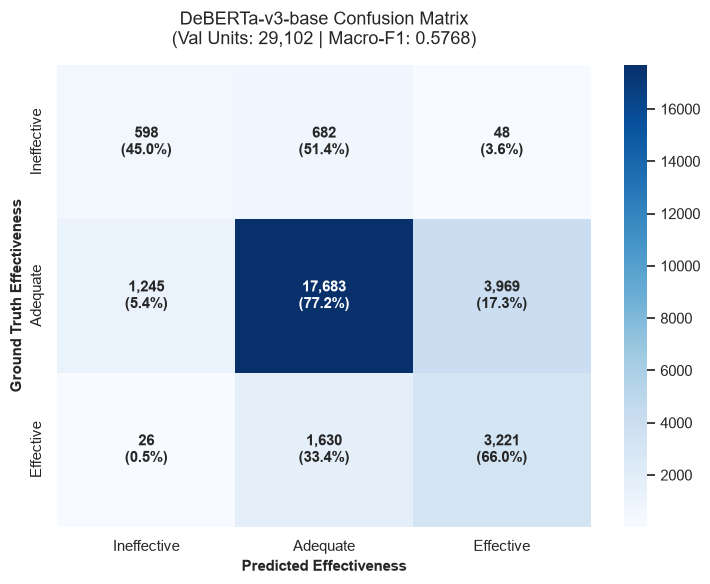


[Baseline] Loading Person 1 classical baseline predictions from: outputs\strongest_baseline_predictions.csv

MODEL PERFORMANCE COMPARISON (SAME VALIDATION PROTOCOL)
                               Model      Split  N_Units  Macro-F1  F1_Ineffective  F1_Adequate  F1_Effective
Classical Baseline (TF-IDF + LogReg) Validation    29102    0.5230          0.2384       0.8591        0.4713
        DeBERTa-v3-base (Fine-tuned) Validation    29102    0.5768          0.3741       0.8245        0.5317

[Statistical Test] Running Paired Cluster Bootstrap (B=2000, Clustered by essay_id)...
[Statistical Test] Rationale: Units within an essay are interdependent; essay-level clustering prevents underestimating SE.


[Statistical Test] Completed 2,000 iterations in 2.28s.
----------------------------------------------------------------------
PAIRED ESSAY-LEVEL BOOTSTRAP HYPOTHESIS TEST RESULTS
----------------------------------------------------------------------
  Delta Definition       : Macro-F1(DeBERTa) - Macro-F1(Classical)
  Mean Delta             : +0.0537
  95% Confidence Interval: [+0.0427, +0.0652]
  Empirical p-value      : 0.0000
  Contains 0?            : False
----------------------------------------------------------------------
[Conclusion] STATISTICALLY SIGNIFICANT: The 95% Confidence Interval [+0.0427, +0.0652] is strictly greater than 0 (p = 0.0000). We reject the null hypothesis and confirm DeBERTa-v3-base achieves statistically superior performance over the classical baseline.



In [5]:
print("\n" + "=" * 80)
print("SECTION 3: VALIDATION EVALUATION & STATISTICAL SIGNIFICANCE TESTING")
print("=" * 80)

# ------------------------------------------------------------------------------
# 3.1 Validation Inference
# ------------------------------------------------------------------------------
print("[Evaluation] Predicting on validation set...")
val_preds_raw = trainer.predict(tokenized_val)
val_logits = val_preds_raw.predictions
if isinstance(val_logits, tuple):
    val_logits = val_logits[0]

# Compute softmax probabilities and predictions
val_probs = scipy.special.softmax(val_logits, axis=-1)
val_preds = np.argmax(val_probs, axis=-1)
val_labels = val_df["label"].values

n_val_essays = val_df["essay_id"].nunique()
n_val_units = len(val_df)

print("\n" + "=" * 70)
print(f"DeBERTa-v3-base on validation: N_essays={n_val_essays:,}, N_units={n_val_units:,}")
print("=" * 70)

deberta_macro_f1 = f1_score(val_labels, val_preds, average="macro", zero_division=0)
deberta_acc = accuracy_score(val_labels, val_preds)
deberta_bal_acc = balanced_accuracy_score(val_labels, val_preds)
deberta_qwk = cohen_kappa_score(val_labels, val_preds, weights="quadratic")
deberta_f1_per_class = f1_score(val_labels, val_preds, average=None, zero_division=0)

print(f"  Macro-F1          : {deberta_macro_f1:.4f}")
print(f"  Accuracy          : {deberta_acc:.4f} ({deberta_acc * 100:.2f}%)")
print(f"  Balanced Accuracy : {deberta_bal_acc:.4f} ({deberta_bal_acc * 100:.2f}%)")
print(f"  Quadratic Kappa   : {deberta_qwk:.4f}")
print("\nPer-Class F1 Breakdown:")
print(f"  * Class 0 (Ineffective) : {deberta_f1_per_class[0]:.4f}")
print(f"  * Class 1 (Adequate)    : {deberta_f1_per_class[1]:.4f}")
print(f"  * Class 2 (Effective)   : {deberta_f1_per_class[2]:.4f}")

print("\n[Classification Report]")
print(classification_report(val_labels, val_preds, target_names=CLASS_NAMES, digits=4))

# ------------------------------------------------------------------------------
# 3.2 Confusion Matrix Heatmap
# ------------------------------------------------------------------------------
cm = confusion_matrix(val_labels, val_preds)
cm_pct = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

labels_annot = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        labels_annot[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})"

plt.figure(figsize=(7.5, 6))
sns.set_theme(style="white")
ax = sns.heatmap(
    cm,
    annot=labels_annot,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    annot_kws={"fontsize": 11, "fontweight": "bold"}
)
plt.title(f"DeBERTa-v3-base Confusion Matrix\n(Val Units: {n_val_units:,} | Macro-F1: {deberta_macro_f1:.4f})", fontsize=13, pad=15)
plt.xlabel("Predicted Effectiveness", fontsize=11, fontweight="bold")
plt.ylabel("Ground Truth Effectiveness", fontsize=11, fontweight="bold")
plt.tight_layout()

cm_fig_path = os.path.join(OUTPUT_DIR, "deberta_confusion_matrix.png")
plt.savefig(cm_fig_path, dpi=300)
print(f"[Plot] Saved confusion matrix heatmap to: {cm_fig_path}")
plt.show()
plt.close()

# ------------------------------------------------------------------------------
# 3.3 Classical Baseline Comparison Setup
# ------------------------------------------------------------------------------
baseline_csv_path = os.path.join(OUTPUT_DIR, "strongest_baseline_predictions.csv")

if os.path.exists(baseline_csv_path):
    print(f"\n[Baseline] Loading Person 1 classical baseline predictions from: {baseline_csv_path}")
    baseline_df = pd.read_csv(baseline_csv_path)
    baseline_df["discourse_id"] = baseline_df["discourse_id"].astype(str).str.strip()
    baseline_df["essay_id"] = baseline_df["essay_id"].astype(str).str.strip()
else:
    print(f"\n[Baseline] '{baseline_csv_path}' not found.")
    print("[Baseline] Generating matching Classical Baseline (TF-IDF + Balanced Logistic Regression) on same split...")
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    
    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=15000, sublinear_tf=True)
    X_tr_tfidf = tfidf.fit_transform(train_df["input_text"])
    X_va_tfidf = tfidf.transform(val_df["input_text"])
    
    base_clf = LogisticRegression(class_weight="balanced", max_iter=1000, C=1.0, random_state=RANDOM_SEED, solver="lbfgs")
    base_clf.fit(X_tr_tfidf, train_df["label"])
    
    base_probs = base_clf.predict_proba(X_va_tfidf)
    base_preds = base_clf.predict(X_va_tfidf)
    
    baseline_df = pd.DataFrame({
        "discourse_id": val_df["discourse_id"].values,
        "essay_id": val_df["essay_id"].values,
        "true_label": val_df["label"].values,
        "pred_label": base_preds,
        "pred_proba_0": base_probs[:, 0],
        "pred_proba_1": base_probs[:, 1],
        "pred_proba_2": base_probs[:, 2]
    })
    baseline_df.to_csv(baseline_csv_path, index=False)
    print(f"[Baseline] Successfully saved classical baseline predictions to: {baseline_csv_path}")

# Normalize baseline predictions, accepting either the standardized integer column
# or Person 1's class-name column.
if "pred_label" in baseline_df.columns:
    baseline_pred = pd.to_numeric(baseline_df["pred_label"], errors="coerce")
elif "discourse_effectiveness_pred" in baseline_df.columns:
    baseline_pred = baseline_df["discourse_effectiveness_pred"].map(LABEL2ID)
else:
    raise KeyError(
        "Baseline predictions need either 'pred_label' or "
        "'discourse_effectiveness_pred'."
    )

if baseline_pred.isna().any():
    bad_values = baseline_df.loc[baseline_pred.isna()].iloc[:, 0].unique()[:10]
    raise ValueError(f"Unrecognized or missing baseline labels: {bad_values}")

# Pair rows using both IDs and only use row order after verifying an exact match.
baseline_discourse_ids = baseline_df["discourse_id"].astype(str).str.strip().to_numpy()
validation_discourse_ids = val_df["discourse_id"].astype(str).str.strip().to_numpy()
baseline_essay_ids = baseline_df["essay_id"].astype(str).str.strip().to_numpy()
validation_essay_ids = val_df["essay_id"].astype(str).str.strip().to_numpy()

rows_match = (
    len(baseline_df) == len(val_df)
    and np.array_equal(baseline_discourse_ids, validation_discourse_ids)
    and np.array_equal(baseline_essay_ids, validation_essay_ids)
)
if not rows_match:
    raise ValueError(
        "Baseline rows do not match validation rows in (essay_id, discourse_id) order."
    )

val_baseline_preds = baseline_pred.to_numpy(dtype=int)

base_macro_f1 = f1_score(val_labels, val_baseline_preds, average="macro", zero_division=0)
base_f1_per_class = f1_score(val_labels, val_baseline_preds, average=None, zero_division=0)

# Build standardized comparison table
comparison_records = [
    {
        "Model": "Classical Baseline (TF-IDF + LogReg)",
        "Split": "Validation",
        "N_Units": n_val_units,
        "Macro-F1": round(base_macro_f1, 4),
        "F1_Ineffective": round(base_f1_per_class[0], 4),
        "F1_Adequate": round(base_f1_per_class[1], 4),
        "F1_Effective": round(base_f1_per_class[2], 4),
    },
    {
        "Model": "DeBERTa-v3-base (Fine-tuned)",
        "Split": "Validation",
        "N_Units": n_val_units,
        "Macro-F1": round(deberta_macro_f1, 4),
        "F1_Ineffective": round(deberta_f1_per_class[0], 4),
        "F1_Adequate": round(deberta_f1_per_class[1], 4),
        "F1_Effective": round(deberta_f1_per_class[2], 4),
    }
]

comparison_df = pd.DataFrame(comparison_records)
print("\n" + "=" * 90)
print("MODEL PERFORMANCE COMPARISON (SAME VALIDATION PROTOCOL)")
print("=" * 90)
print(comparison_df.to_string(index=False))
print("=" * 90)

# ------------------------------------------------------------------------------
# 3.4 Paired Cluster Bootstrap (Clustered by essay_id, B=2000)
# ------------------------------------------------------------------------------
print(f"\n[Statistical Test] Running Paired Cluster Bootstrap (B={args.bootstrap_b}, Clustered by essay_id)...")
print("[Statistical Test] Rationale: Units within an essay are interdependent; essay-level clustering prevents underestimating SE.")

def fast_macro_f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Exact, vectorized 3-class Macro-F1 via bincount for high-speed bootstrap."""
    cm_fast = np.bincount(y_true * 3 + y_pred, minlength=9).reshape(3, 3)
    tp = np.diag(cm_fast)
    fp = np.sum(cm_fast, axis=0) - tp
    fn = np.sum(cm_fast, axis=1) - tp
    denom = 2 * tp + fp + fn
    f1_c = np.where(denom > 0, (2.0 * tp) / denom, 0.0)
    return float(np.mean(f1_c))

# Pre-index unit positions by essay_id for O(1) cluster extraction
essay_groups = val_df.groupby("essay_id").indices
unique_val_essays = np.array(list(essay_groups.keys()))
n_clusters = len(unique_val_essays)

bootstrap_rng = np.random.default_rng(RANDOM_SEED)
bootstrap_deltas: List[float] = []

boot_start = time.time()
for b in range(args.bootstrap_b):
    # Resample essays with replacement
    sampled_essays = bootstrap_rng.choice(unique_val_essays, size=n_clusters, replace=True)
    # Collect all unit row indices belonging to sampled essays
    unit_indices = np.concatenate([essay_groups[eid] for eid in sampled_essays])
    
    y_true_b = val_labels[unit_indices]
    y_deb_b = val_preds[unit_indices]
    y_base_b = val_baseline_preds[unit_indices]
    
    f1_deb = fast_macro_f1(y_true_b, y_deb_b)
    f1_base = fast_macro_f1(y_true_b, y_base_b)
    bootstrap_deltas.append(f1_deb - f1_base)

boot_duration = time.time() - boot_start
deltas_arr = np.array(bootstrap_deltas)

mean_delta = float(np.mean(deltas_arr))
ci_low = float(np.percentile(deltas_arr, 2.5))
ci_high = float(np.percentile(deltas_arr, 97.5))
p_value_empirical = float(np.mean(deltas_arr <= 0))
ci_contains_zero = bool(ci_low <= 0.0 <= ci_high)

print(f"[Statistical Test] Completed {args.bootstrap_b:,} iterations in {boot_duration:.2f}s.")
print("-" * 70)
print(f"PAIRED ESSAY-LEVEL BOOTSTRAP HYPOTHESIS TEST RESULTS")
print("-" * 70)
print(f"  Delta Definition       : Macro-F1(DeBERTa) - Macro-F1(Classical)")
print(f"  Mean Delta             : {mean_delta:+.4f}")
print(f"  95% Confidence Interval: [{ci_low:+.4f}, {ci_high:+.4f}]")
print(f"  Empirical p-value      : {p_value_empirical:.4f}")
print(f"  Contains 0?            : {ci_contains_zero}")
print("-" * 70)

if not ci_contains_zero and ci_low > 0:
    conclusion_text = (
        f"STATISTICALLY SIGNIFICANT: The 95% Confidence Interval [{ci_low:+.4f}, {ci_high:+.4f}] "
        f"is strictly greater than 0 (p = {p_value_empirical:.4f}). We reject the null hypothesis "
        f"and confirm DeBERTa-v3-base achieves statistically superior performance over the classical baseline."
    )
elif ci_contains_zero:
    conclusion_text = (
        f"INCONCLUSIVE: The 95% Confidence Interval [{ci_low:+.4f}, {ci_high:+.4f}] contains 0 "
        f"(p = {p_value_empirical:.4f}). We CANNOT claim DeBERTa is statistically significantly better than the classical baseline."
    )
else:
    conclusion_text = (
        f"STATISTICALLY INFERIOR: The 95% Confidence Interval [{ci_low:+.4f}, {ci_high:+.4f}] is strictly negative. "
        f"DeBERTa underperforms the classical baseline."
    )

print(f"[Conclusion] {conclusion_text}\n")



### Section 4: Calibration Analysis & Temperature Scaling
In this section, we:
1. Evaluate Model Calibration via Expected Calibration Error (ECE) using 10 equal-width confidence bins.
2. Prevent data contamination by splitting validation essays into:
   - 20% Calibration Set (where Temperature $T$ is fitted via Negative Log-Likelihood minimization).
   - 80% Report Set (where uncalibrated vs calibrated ECE and Reliability Diagrams are evaluated).
3. Fit post-hoc Temperature Scaling $T^* > 0$:
   $$P(Y = k | z) = \frac{\exp(z_k / T)}{\sum_j \exp(z_j / T)}$$
4. Generate multi-panel Reliability Diagrams for all three classes (Ineffective, Adequate, Effective),
   comparing empirical accuracy against predicted confidence before and after calibration.



SECTION 4: CALIBRATION ANALYSIS & TEMPERATURE SCALING
[Calibration Protocol] Splitting validation set into 20% calibration and 80% reporting splits by essay_id...
  * Calibration Split (20%): 5,954 units across 623 essays (FITTING TEMPERATURE)
  * Report Split      (80%): 23,148 units across 2,496 essays (EVALUATING CALIBRATION)

[Calibration] Optimal Temperature T* fitted on 20% validation split: 1.1244
-----------------------------------------------------------------
CALIBRATION ERROR (ECE) EVALUATED ON 80% REPORT SPLIT
-----------------------------------------------------------------
  Uncalibrated ECE (10 bins) : 1.53% (0.0153)
  Calibrated ECE (T=1.12)  : 1.66% (0.0166)
  Relative ECE Reduction     : -8.79%
-----------------------------------------------------------------
[Plot] Generating 3-class Reliability Diagrams on 80% Report split...


[Plot] Saved reliability diagrams to: outputs\deberta_calibration_reliability_diagrams.png


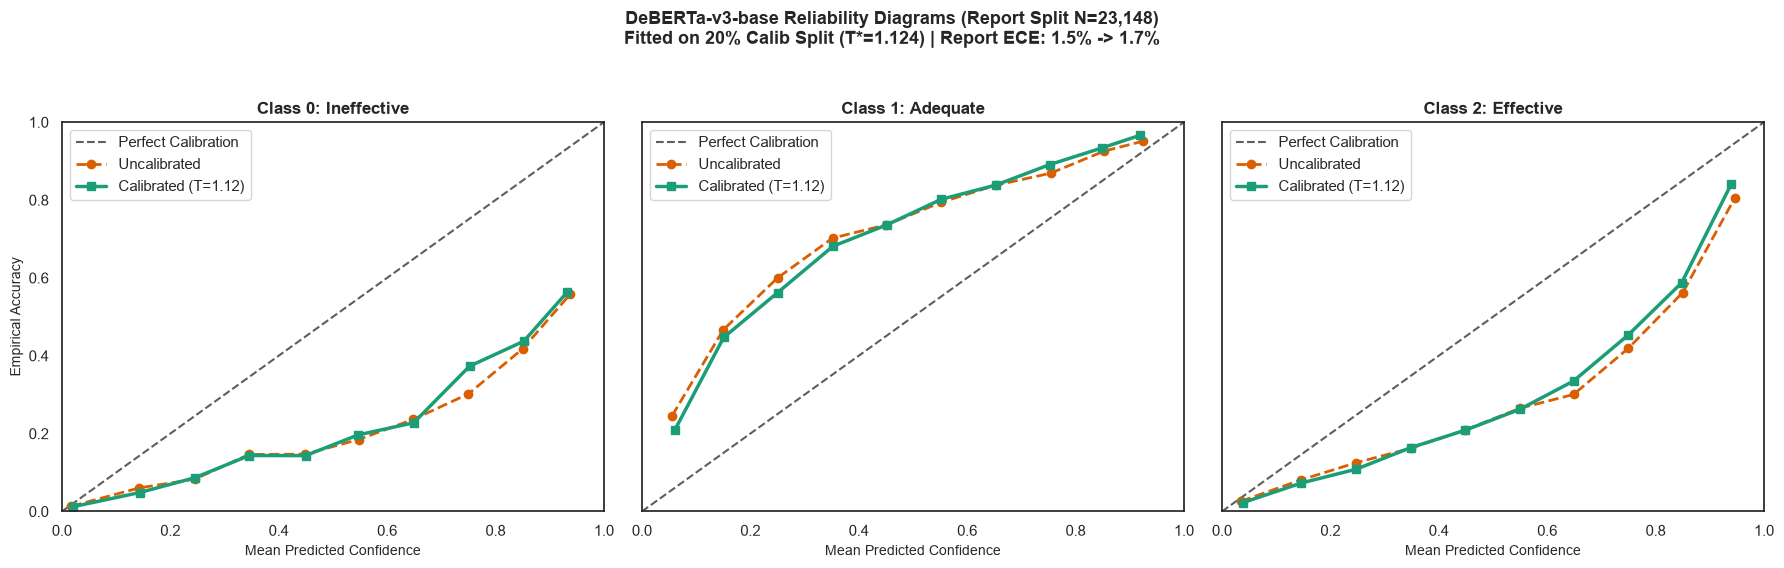

In [6]:
print("\n" + "=" * 80)
print("SECTION 4: CALIBRATION ANALYSIS & TEMPERATURE SCALING")
print("=" * 80)

def compute_multiclass_ece(probs: np.ndarray, labels: np.ndarray, n_bins: int = 10) -> Tuple[float, List[Dict[str, Any]]]:
    """
    Compute Expected Calibration Error (ECE) with equal-width confidence bins.
    """
    confidences = np.max(probs, axis=-1)
    predictions = np.argmax(probs, axis=-1)
    accuracies = (predictions == labels).astype(float)
    
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_details = []
    
    for i in range(n_bins):
        low, high = bin_edges[i], bin_edges[i + 1]
        if i == n_bins - 1:
            in_bin = (confidences >= low) & (confidences <= high)
        else:
            in_bin = (confidences >= low) & (confidences < high)
            
        count = int(np.sum(in_bin))
        if count > 0:
            bin_acc = float(np.mean(accuracies[in_bin]))
            bin_conf = float(np.mean(confidences[in_bin]))
            bin_gap = abs(bin_acc - bin_conf)
            ece += (count / len(labels)) * bin_gap
            bin_details.append({
                "bin": i,
                "range": f"[{low:.1f}, {high:.1f}]",
                "count": count,
                "acc": bin_acc,
                "conf": bin_conf,
                "gap": bin_gap
            })
    return float(ece), bin_details

# ------------------------------------------------------------------------------
# 4.1 Split Validation into 20% Calibration and 80% Report Sets
# ------------------------------------------------------------------------------
print("[Calibration Protocol] Splitting validation set into 20% calibration and 80% reporting splits by essay_id...")

gss_cal = GroupShuffleSplit(n_splits=1, test_size=0.80, random_state=RANDOM_SEED)
calib_idx, report_idx = next(gss_cal.split(val_df, groups=val_df["essay_id"]))

calib_essays = val_df.iloc[calib_idx]["essay_id"].nunique()
report_essays = val_df.iloc[report_idx]["essay_id"].nunique()

print(f"  * Calibration Split (20%): {len(calib_idx):,} units across {calib_essays:,} essays (FITTING TEMPERATURE)")
print(f"  * Report Split      (80%): {len(report_idx):,} units across {report_essays:,} essays (EVALUATING CALIBRATION)")

calib_logits = val_logits[calib_idx]
calib_labels = val_labels[calib_idx]

report_logits = val_logits[report_idx]
report_labels = val_labels[report_idx]

# ------------------------------------------------------------------------------
# 4.2 Fit Temperature Scaling Parameter via NLL Minimization
# ------------------------------------------------------------------------------
def temperature_nll(t_val, logits, labels):
    t = t_val[0] if hasattr(t_val, "__len__") else t_val
    scaled_logits = logits / max(t, 1e-4)
    log_probs = scaled_logits - scipy.special.logsumexp(scaled_logits, axis=-1, keepdims=True)
    nll = -np.mean(log_probs[np.arange(len(labels)), labels])
    return nll

res_temp = scipy.optimize.minimize(
    temperature_nll,
    x0=[1.0],
    args=(calib_logits, calib_labels),
    bounds=[(0.05, 10.0)],
    method="L-BFGS-B"
)

fitted_temperature = float(res_temp.x[0])
print(f"\n[Calibration] Optimal Temperature T* fitted on 20% validation split: {fitted_temperature:.4f}")

# ------------------------------------------------------------------------------
# 4.3 Evaluate ECE on Isolated 80% Report Set
# ------------------------------------------------------------------------------
report_probs_uncal = scipy.special.softmax(report_logits, axis=-1)
report_probs_cal = scipy.special.softmax(report_logits / fitted_temperature, axis=-1)

ece_uncal, _ = compute_multiclass_ece(report_probs_uncal, report_labels, n_bins=10)
ece_cal, _ = compute_multiclass_ece(report_probs_cal, report_labels, n_bins=10)
ece_improvement = (ece_uncal - ece_cal) / max(ece_uncal, 1e-6) * 100

print("-" * 65)
print("CALIBRATION ERROR (ECE) EVALUATED ON 80% REPORT SPLIT")
print("-" * 65)
print(f"  Uncalibrated ECE (10 bins) : {ece_uncal * 100:.2f}% ({ece_uncal:.4f})")
print(f"  Calibrated ECE (T={fitted_temperature:.2f})  : {ece_cal * 100:.2f}% ({ece_cal:.4f})")
print(f"  Relative ECE Reduction     : {ece_improvement:+.2f}%")
print("-" * 65)

# ------------------------------------------------------------------------------
# 4.4 Plot Reliability Diagrams for All 3 Classes
# ------------------------------------------------------------------------------
print("[Plot] Generating 3-class Reliability Diagrams on 80% Report split...")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
sns.set_theme(style="whitegrid")

for c_idx, c_name in enumerate(CLASS_NAMES):
    ax = axes[c_idx]
    y_true_binary = (report_labels == c_idx).astype(float)
    p_uncal = report_probs_uncal[:, c_idx]
    p_cal = report_probs_cal[:, c_idx]
    
    bin_edges = np.linspace(0.0, 1.0, 11)
    uncal_conf_vals, uncal_acc_vals = [], []
    cal_conf_vals, cal_acc_vals = [], []
    
    for b in range(10):
        low, high = bin_edges[b], bin_edges[b + 1]
        
        # Uncalibrated bin
        in_uncal = (p_uncal >= low) & (p_uncal <= high if b == 9 else p_uncal < high)
        if np.sum(in_uncal) > 0:
            uncal_conf_vals.append(np.mean(p_uncal[in_uncal]))
            uncal_acc_vals.append(np.mean(y_true_binary[in_uncal]))
            
        # Calibrated bin
        in_cal = (p_cal >= low) & (p_cal <= high if b == 9 else p_cal < high)
        if np.sum(in_cal) > 0:
            cal_conf_vals.append(np.mean(p_cal[in_cal]))
            cal_acc_vals.append(np.mean(y_true_binary[in_cal]))
            
    # Reference perfect calibration line
    ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration", linewidth=1.5, alpha=0.7)
    
    # Curves
    if uncal_conf_vals:
        ax.plot(uncal_conf_vals, uncal_acc_vals, "o--", color="#d95f02", label="Uncalibrated", linewidth=2, markersize=6)
    if cal_conf_vals:
        ax.plot(cal_conf_vals, cal_acc_vals, "s-", color="#1b9e77", label=f"Calibrated (T={fitted_temperature:.2f})", linewidth=2.5, markersize=6)
        
    ax.set_title(f"Class {c_idx}: {c_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Mean Predicted Confidence", fontsize=10)
    if c_idx == 0:
        ax.set_ylabel("Empirical Accuracy", fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", frameon=True)

plt.suptitle(
    f"DeBERTa-v3-base Reliability Diagrams (Report Split N={len(report_idx):,})\n"
    f"Fitted on 20% Calib Split (T*={fitted_temperature:.3f}) | Report ECE: {ece_uncal*100:.1f}% -> {ece_cal*100:.1f}%",
    fontsize=13,
    fontweight="bold",
    y=1.03
)
plt.tight_layout()

rel_diag_path = os.path.join(OUTPUT_DIR, "deberta_calibration_reliability_diagrams.png")
plt.savefig(rel_diag_path, dpi=300, bbox_inches="tight")
print(f"[Plot] Saved reliability diagrams to: {rel_diag_path}")
plt.show()
plt.close()


### Section 5: Save Outputs
In this final section, we export all deliverables to the `outputs/` directory:
1. Predictions CSV:
   `outputs/deberta_predictions.csv`
   Containing `[discourse_id, essay_id, true_label, pred_label, pred_proba_0, pred_proba_1, pred_proba_2]`
2. Comparison Table CSV:
   `outputs/model_comparison_table.csv`
3. Bootstrap Results JSON:
   `outputs/bootstrap_paired_test_results.json`
4. Model Checkpoint Metadata JSON:
   `outputs/model_checkpoint_info.json`


In [7]:
print("\n" + "=" * 80)
print("SECTION 5: EXPORTING PRODUCTION ARTIFACTS & DELIVERABLES")
print("=" * 80)

# ------------------------------------------------------------------------------
# 5.1 Save Predictions CSV
# ------------------------------------------------------------------------------
pred_export_path = os.path.join(OUTPUT_DIR, "deberta_predictions.csv")
predictions_df = pd.DataFrame({
    "discourse_id": val_df["discourse_id"].values,
    "essay_id": val_df["essay_id"].values,
    "true_label": val_labels,
    "pred_label": val_preds,
    "pred_proba_0": np.round(val_probs[:, 0], 6),
    "pred_proba_1": np.round(val_probs[:, 1], 6),
    "pred_proba_2": np.round(val_probs[:, 2], 6),
})
predictions_df.to_csv(pred_export_path, index=False)
print(f"[Export] 1. Validation predictions CSV saved to: {pred_export_path} ({len(predictions_df):,} rows)")

# ------------------------------------------------------------------------------
# 5.2 Save Comparison Table CSV
# ------------------------------------------------------------------------------
comp_export_path = os.path.join(OUTPUT_DIR, "model_comparison_table.csv")
comparison_df.to_csv(comp_export_path, index=False)
print(f"[Export] 2. Model comparison table CSV saved to: {comp_export_path}")

# ------------------------------------------------------------------------------
# 5.3 Save Bootstrap Results JSON
# ------------------------------------------------------------------------------
boot_export_path = os.path.join(OUTPUT_DIR, "bootstrap_paired_test_results.json")
bootstrap_payload = {
    "iterations_B": args.bootstrap_b,
    "cluster_entity": "essay_id",
    "cluster_count_essays": int(n_clusters),
    "sample_size_units": int(n_val_units),
    "deberta_macro_f1": float(deberta_macro_f1),
    "classical_baseline_macro_f1": float(base_macro_f1),
    "delta_definition": "Macro_F1(DeBERTa) - Macro_F1(Classical)",
    "delta_mean": float(mean_delta),
    "ci_95_lower": float(ci_low),
    "ci_95_upper": float(ci_high),
    "empirical_p_value": float(p_value_empirical),
    "ci_contains_zero": bool(ci_contains_zero),
    "is_statistically_significant": bool(not ci_contains_zero and ci_low > 0),
    "conclusion": conclusion_text,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
}

with open(boot_export_path, "w", encoding="utf-8") as f_boot:
    json.dump(bootstrap_payload, f_boot, indent=2)
print(f"[Export] 3. Bootstrap paired statistical results JSON saved to: {boot_export_path}")

# ------------------------------------------------------------------------------
# 5.4 Save Model Checkpoint Metadata JSON
# ------------------------------------------------------------------------------
meta_export_path = os.path.join(OUTPUT_DIR, "model_checkpoint_info.json")
checkpoint_metadata = {
    "model_architecture": MODEL_NAME,
    "task": "Discourse Effectiveness 3-Class Classification",
    "num_labels": 3,
    "label_mapping": LABEL2ID,
    "max_sequence_length": MAX_LENGTH,
    "class_weights": [float(w) for w in computed_weights],
    "hyperparameters": {
        "learning_rate": args.lr,
        "train_batch_size": args.batch_size,
        "gradient_accumulation_steps": args.grad_accum,
        "effective_batch_size": args.batch_size * args.grad_accum,
        "epochs": train_epochs,
        "warmup_ratio": 0.1,
        "fp16": USE_FP16,
        "metric_for_best_model": "macro_f1",
        "random_seed": RANDOM_SEED,
    },
    "validation_performance": {
        "macro_f1": float(deberta_macro_f1),
        "accuracy": float(deberta_acc),
        "balanced_accuracy": float(deberta_bal_acc),
        "quadratic_weighted_kappa": float(deberta_qwk),
        "f1_ineffective": float(deberta_f1_per_class[0]),
        "f1_adequate": float(deberta_f1_per_class[1]),
        "f1_effective": float(deberta_f1_per_class[2]),
    },
    "calibration": {
        "fitted_temperature": float(fitted_temperature),
        "calib_split_ratio": 0.20,
        "report_split_ratio": 0.80,
        "report_ece_uncalibrated": float(ece_uncal),
        "report_ece_calibrated": float(ece_cal),
        "relative_ece_reduction_percent": float(ece_improvement),
    },
    "hardware_environment": {
        "device": str(DEVICE),
        "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None",
        "fp16_enabled": USE_FP16,
    },
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
}

with open(meta_export_path, "w", encoding="utf-8") as f_meta:
    json.dump(checkpoint_metadata, f_meta, indent=2)
print(f"[Export] 4. Model checkpoint metadata JSON saved to: {meta_export_path}")

# ------------------------------------------------------------------------------
# Final Execution Summary
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("PIPELINE EXECUTION COMPLETE: ALL ARTIFACTS VERIFIED AND PERSISTED")
print("=" * 80)
print(f"  * Predictions File  : {pred_export_path}")
print(f"  * Comparison Table  : {comp_export_path}")
print(f"  * Bootstrap Results : {boot_export_path}")
print(f"  * Checkpoint Info   : {meta_export_path}")
print(f"  * Confusion Matrix  : {cm_fig_path}")
print(f"  * Reliability Plot  : {rel_diag_path}")
print("=" * 80)


SECTION 5: EXPORTING PRODUCTION ARTIFACTS & DELIVERABLES
[Export] 1. Validation predictions CSV saved to: outputs\deberta_predictions.csv (29,102 rows)
[Export] 2. Model comparison table CSV saved to: outputs\model_comparison_table.csv
[Export] 3. Bootstrap paired statistical results JSON saved to: outputs\bootstrap_paired_test_results.json
[Export] 4. Model checkpoint metadata JSON saved to: outputs\model_checkpoint_info.json

PIPELINE EXECUTION COMPLETE: ALL ARTIFACTS VERIFIED AND PERSISTED
  * Predictions File  : outputs\deberta_predictions.csv
  * Comparison Table  : outputs\model_comparison_table.csv
  * Bootstrap Results : outputs\bootstrap_paired_test_results.json
  * Checkpoint Info   : outputs\model_checkpoint_info.json
  * Confusion Matrix  : outputs\deberta_confusion_matrix.png
  * Reliability Plot  : outputs\deberta_calibration_reliability_diagrams.png
